In [2]:
#Importing necessary libraries
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import scipy
import netCDF4
import pymannkendall as mk
'''To group the data into chillai kalan dictionary so I can retrieve it easily for plotting and analysis and 
to store temp in celsius and calculate daily minimum temperature and then extract daily minimum for all the grid
for all the years in our study (i.e. 1981-2025)'''
ck = {}
ck2 = {}
dmin = {}
dmax= {}
for n in range(1981, 2026):

    dec1 = xr.open_dataset(f"raw data/Dec{n-1}.nc")
    jan1 = xr.open_dataset(f"raw data/Jan{n}.nc")
    dec = dec1.sel(valid_time=slice(f"{n-1}-12-21", f"{n-1}-12-31"))
    jan = jan1.sel(valid_time=slice(f"{n}-01-01", f"{n}-01-29"))
    ck[n] = xr.concat([dec, jan], dim="valid_time", join="exact")
    ck2[n] = ck[n].t2m - 273.15
    ck2[n].attrs["units"] = "°C"
    dmin[n] = ck2[n].resample(valid_time="1D").min()
    dmax[n] = ck2[n].resample(valid_time="1D").max()

print('hello')

hello


In [3]:
'''Truncating daily min temp and daily max temp according to different stations'''
s_dmin = {"srinagar": {}, "gulmarg": {}, "pahalgam": {}, "baramulla": {}, "kupwara": {}, "qazigund": {}}
s_dmax = {"srinagar": {}, "gulmarg": {}, "pahalgam": {}, "baramulla": {}, "kupwara": {}, "qazigund": {}}

def station(data_dict, lat1, lat2, lon1, lon2):
    out = {}
    for year in data_dict:
        out[year] = data_dict[year].sel(latitude=slice(lat1, lat2), longitude=slice(lon1, lon2))
    return out   
s_dmin["srinagar"] = station(dmin, 34.2, 34.0, 74.7, 74.9)
s_dmax["srinagar"] = station(dmax, 34.2, 34.0, 74.7, 74.9)
s_dmin["gulmarg"] = station(dmin, 34.1, 33.9, 74.3, 74.5)
s_dmax["gulmarg"] = station(dmax, 34.1, 33.9, 74.3, 74.5)
s_dmin["pahalgam"] = station(dmin, 34.1, 33.9, 75.2, 75.4)
s_dmax["pahalgam"] = station(dmax, 34.1, 33.9, 75.2, 75.4)
s_dmin["baramulla"] = station(dmin, 34.3, 34.1, 74.3, 74.5)
s_dmax["baramulla"] = station(dmax, 34.3, 34.1, 74.3, 74.5)
s_dmin["kupwara"] = station(dmin, 34.1, 34.0, 74.2, 74.3)
s_dmax["kupwara"] = station(dmax, 34.1, 34.0, 74.2, 74.3)
s_dmin["qazigund"] = station(dmin, 33.7, 33.5, 75.0, 75.2)
s_dmax["qazigund"] = station(dmax, 33.7, 33.5, 75.0, 75.2)


In [4]:
'''To take average of minimum temperature over particular stations (ACTUAL DAILY Tmin)'''
m_tmin = {"srinagar": {}, "gulmarg": {}, "pahalgam": {}, "baramulla": {}, "kupwara": {}, "qazigund": {}}
def stat_mean(data_dict):
    out = {}
    for year in data_dict:
        out[year]= data_dict[year].mean(dim=["latitude", "longitude"])
    return out
for station in ["srinagar", "gulmarg", "pahalgam", "baramulla", "kupwara", "qazigund"]:
    m_tmin[station]= stat_mean(s_dmin[station])

In [5]:
'''To take average of maximum temperature over particular stations (ACTUAL DAILY Tmin)'''
m_tmax = {"srinagar": {}, "gulmarg": {}, "pahalgam": {}, "baramulla": {}, "kupwara": {}, "qazigund": {}}
def stat_mean(data_dict):
    out = {}
    for year in data_dict:
        out[year]= data_dict[year].mean(dim=["latitude", "longitude"])
    return out
for station in ["srinagar", "gulmarg", "pahalgam", "baramulla", "kupwara", "qazigund"]:
    m_tmax[station]= stat_mean(s_dmax[station])

In [6]:
'''To calculate Diurnal Temperature Range'''
dtr = {"srinagar": {}, "gulmarg": {}, "pahalgam": {}, "baramulla": {}, "kupwara": {}, "qazigund": {}}
dtr_mean = {"srinagar": {}, "gulmarg": {}, "pahalgam": {}, "baramulla": {}, "kupwara": {}, "qazigund": {}}

for n in dtr:
    
    for y in range (1981, 2026):
        out = {}
        for d in range(40):
            out[d] = m_tmax[n][y][d].item() - m_tmin[n][y][d].item()
        dtr[n][y] = out
        dtr_mean[n][y] = np.mean(list(dtr[n][y].values()))


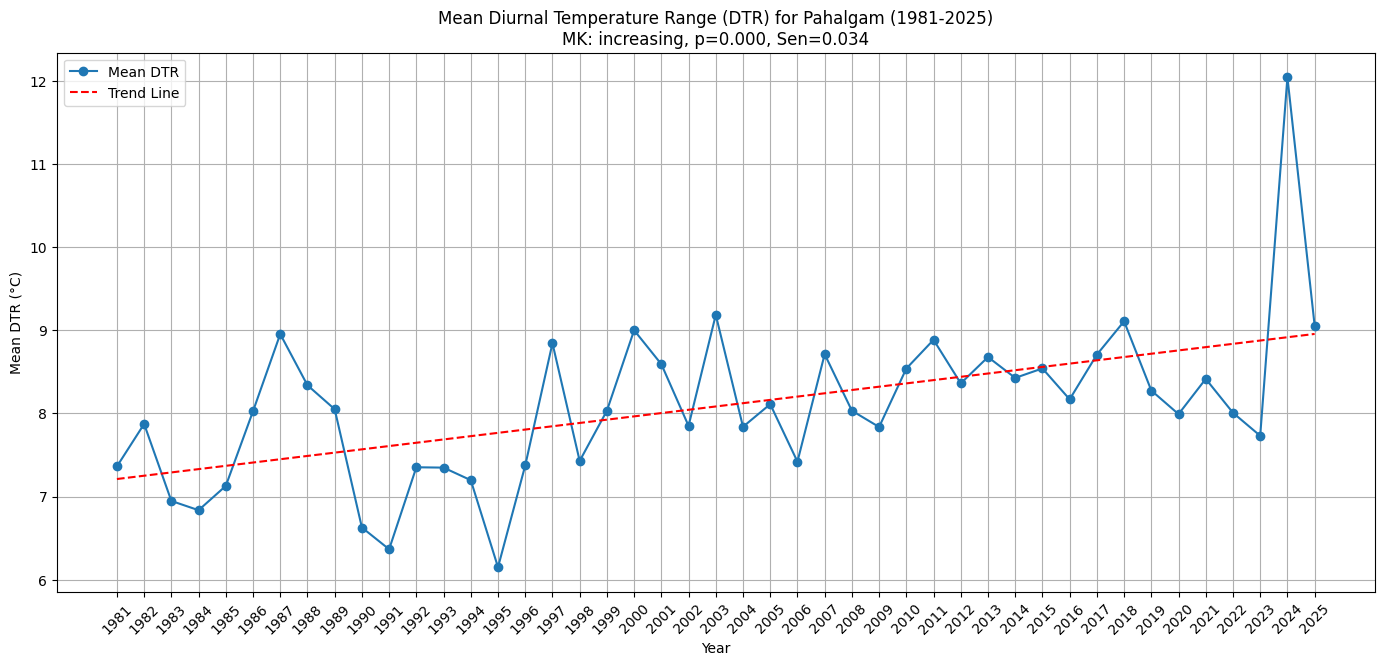

In [7]:
'''Plotting dtr_mean for each station'''
def plot_dtr_mean(place):
    years = np.arange(1981, 2026)
    z = [dtr_mean[place][y] for y in years]
    
    m, c = np.polyfit(years, z, 1)
    trend = m*years + c
    
    result = mk.original_test(z)
    
    plt.figure(figsize=(17, 7))
    plt.plot(years, z, marker='o', label='Mean DTR')
    plt.plot(years, trend, color='red', linestyle='--', label='Trend Line')
    
    plt.title(f'Mean Diurnal Temperature Range (DTR) for {place.title()} (1981-2025)\nMK: {result.trend}, p={result.p:.3f}, Sen={result.slope:.3f}')
    plt.xlabel('Year')
    plt.ylabel('Mean DTR (°C)')
    plt.xticks(years, rotation=45)
    plt.legend()
    plt.grid(True)

plot_dtr_mean("pahalgam")

In [8]:
'''Normal minimum temperature for particular chillai kalan days for all years'''
nt = {"srinagar": [], "gulmarg": [], "pahalgam": [], "baramulla": [], "kupwara": [], "qazigund": []}
def norm(data):
    out = []
    for n in range (0, 40):
        s = 0
        for i in range (1991, 2021):
            s = s + data[i][n].item()
        out.append(s/30)
    return(out)
for station in ["srinagar", "gulmarg", "pahalgam", "baramulla", "kupwara", "qazigund"]:
    nt[station] = norm(m_tmin[station])

In [9]:
'''To find the departure or anomaly in a day -- how much deviation is there in the daily minimum temperature'''
dep = {"srinagar": {}, "gulmarg": {}, "pahalgam": {}, "baramulla": {}, "kupwara": {}, "qazigund": {}}

def anomaly(place):
    for year in range (1981, 2026):
        dep[place][year] = {}
        for day in range (0,40):
            dep[place][year][day] = m_tmin[place][year][day].item() - nt[place][day]

for station in ["srinagar", "gulmarg", "pahalgam", "baramulla", "kupwara", "qazigund"]:
    anomaly(station)

In [10]:
'''To calculate number of cold wave days from certain criterions according to IMD'''
cw = {"srinagar": {}, "gulmarg": {}, "pahalgam": {}, "baramulla": {}, "kupwara": {}, "qazigund": {}}
scw = {"srinagar": {}, "gulmarg": {}, "pahalgam": {}, "baramulla": {}, "kupwara": {}, "qazigund": {}}
tcw= {"srinagar": {}, "gulmarg": {}, "pahalgam": {}, "baramulla": {}, "kupwara": {}, "qazigund": {}}
fd = {"srinagar": {}, "gulmarg": {}, "pahalgam": {}, "baramulla": {}, "kupwara": {}, "qazigund": {}}
def cw_day(place):
    for year in range (1981, 2026):
        scw1 = 0 
        cw1 = 0
        fd1 = 0
        for day in range (0, 40):
            
            if m_tmin[place][year][day].item() <=0 :
                if dep[place][year][day] <= -6.5 :
                    scw1 += 1
                elif dep[place][year][day] <= -4.5  and dep[place][year][day]>= -6.5:
                    cw1 +=1
            if m_tmin[place][year][day].item() <= 0 :
                fd1 += 1
        cw[place][year] = cw1
        scw[place][year] = scw1
        tcw[place][year] = cw1 + scw1
        fd[place][year] = fd1

for place in ["srinagar","gulmarg", "pahalgam", "baramulla", "kupwara", "qazigund"]:
    cw_day(place) 


In [11]:
'''To find no of consecutive cold spell days to calculate csdi'''
csdi = {"srinagar": {}, "gulmarg": {}, "pahalgam": {}, "baramulla": {}, "kupwara": {}, "qazigund": {}}

def coldspell():
    
    for n in csdi:
        for y in range (1981, 2026):
            cocd = 0
            b = 0
            s = 0
            for i in range(40):
                t=m_tmin[n][y][i].item()
                d=dep[n][y][i]

                if t<= 0 and d<= -4.5:
                    cocd +=1
                    if cocd >= 3:
                        b = cocd
                else: 
                    cocd=0
                    s=s+b
                    b=0            
            csdi[n][y] = s + b

coldspell()


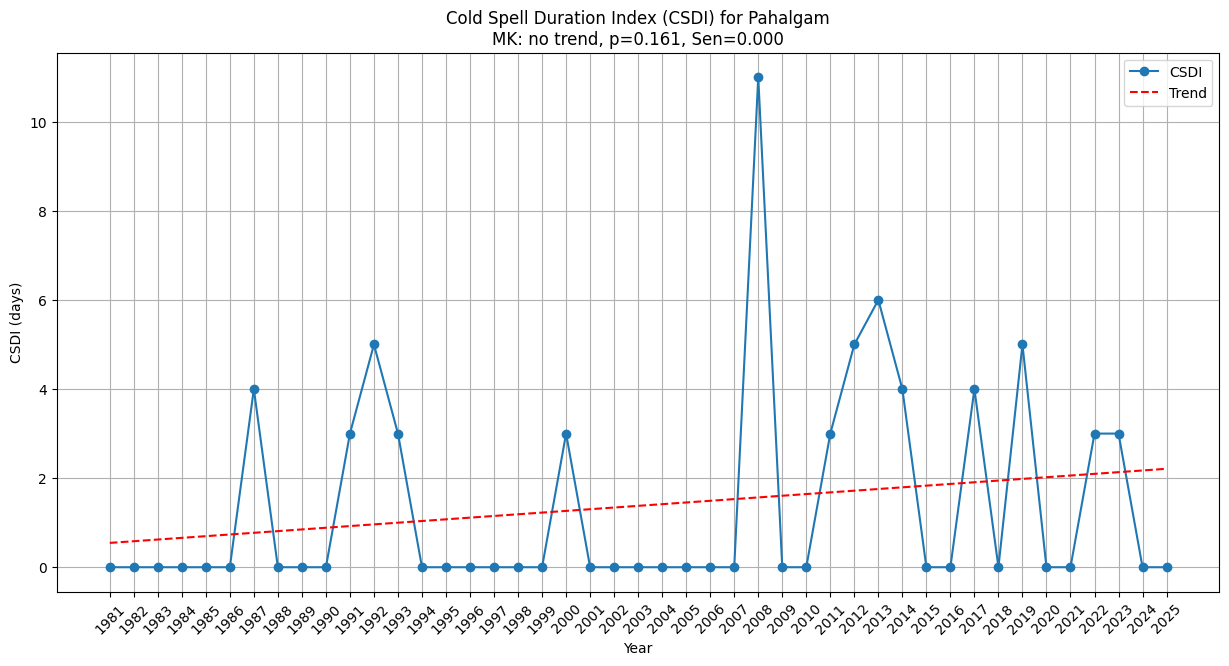

In [12]:
'''Plotting csdi for a particular station'''
def plot_csdi(place):
    years = np.arange(1981, 2026)
    z = [csdi[place][y] for y in years]
    
    m, c = np.polyfit(years, z, 1)
    trend = m*years + c

    result = mk.original_test(z)
    
    plt.figure(figsize=(15, 7))
    plt.plot(years, z, marker='o', label='CSDI')
    plt.plot(years, trend, color='red', linestyle='--', label='Trend')
    
    plt.title(f'Cold Spell Duration Index (CSDI) for {place.title()}\nMK: {result.trend}, p={result.p:.3f}, Sen={result.slope:.3f}')
    plt.xlabel('Year')
    plt.ylabel('CSDI (days)')
    plt.xticks(years, rotation=45)
    plt.legend()
    plt.grid(True)

plot_csdi("pahalgam")

In [13]:
'''To find lowest temperature each season'''
tnn = {"srinagar": {}, "gulmarg": {}, "pahalgam": {}, "baramulla": {}, "kupwara": {}, "qazigund": {}} #lowest min temp
tnm = {"srinagar": {}, "gulmarg": {}, "pahalgam": {}, "baramulla": {}, "kupwara": {}, "qazigund": {}} #mean of min temp
def lowT(place):
    for year in range(1981, 2026):
        tnm[place][year] = m_tmin[place][year].mean().values  #mean of min temp
        tnn[place][year] = m_tmin[place][year].min().values  #lowest min temp
for place in ["srinagar", "gulmarg", "pahalgam", "baramulla", "kupwara", "qazigund"]:
    lowT(place)
print(tnn["srinagar"][1981])

-12.028778


In [14]:
'''To count percentage of days where Tmin is below the 10th percentile of baseline'''
tn10 = {"srinagar": {}, "gulmarg": {}, "pahalgam": {}, "baramulla": {}, "kupwara": {}, "qazigund": {}}
p10 = {"srinagar": {}, "gulmarg": {}, "pahalgam": {}, "baramulla": {}, "kupwara": {}, "qazigund": {}}
p90 = {"srinagar": {}, "gulmarg": {}, "pahalgam": {}, "baramulla": {}, "kupwara": {}, "qazigund": {}}
tn90 = {"srinagar": {}, "gulmarg": {}, "pahalgam": {}, "baramulla": {}, "kupwara": {}, "qazigund": {}}

def percentile10(place):
    out = []
    for day in range(0, 40):
        vals = []
        for year in range(1991, 2021):
            vals.append(m_tmin[place][year][day].item())
        out.append(np.percentile(vals, 10))
    p10[place] = out

def percentile90(place):
    out = []
    for day in range(0, 40):
        vals = []
        for year in range(1991, 2021):
            vals.append(m_tmin[place][year][day].item())
        out.append(np.percentile(vals, 90))
    p90[place] = out

for place in p10:
    percentile10(place)
for place in p90:
    percentile90(place)

def cw_percentile(place):
    for year in range(1981, 2026):
        c = 0
        w = 0
        for day in range(40):
            t = m_tmin[place][year][day].item()

            if t <= p10[place][day]:
                c += 1

            if t >= p90[place][day]:
                w += 1
        tn10[place][year] = c
        tn90[place][year] = w

for place in tn10:
    cw_percentile(place)



In [15]:
'''To calculate how many consequtive cold spell days have '''
csdi10= {"srinagar": {}, "gulmarg": {}, "pahalgam": {}, "baramulla": {}, "kupwara": {}, "qazigund": {}}

def calc_csdi(place):

    for year in range(1981, 2026):
        run = 0
        total = 0
        for day in range(40):
            t = m_tmin[place][year][day].item()
            if t <= p10[place][day]:
                run += 1
            else:
                if run >= 6:
                    total += run
                run = 0
        # handle run reaching the last day
        if run >= 6:
            total += run
        csdi10[place][year] = total

In [16]:
'''To calculate how many consequtive warm spell days have '''
wsdi90 = {"srinagar": {}, "gulmarg": {}, "pahalgam": {}, "baramulla": {}, "kupwara": {}, "qazigund": {}}
pmax90 = {"srinagar": {}, "gulmarg": {}, "pahalgam": {}, "baramulla": {}, "kupwara": {}, "qazigund": {}}

def percentile90(place):
    out = []
    for day in range(0, 40):
        vals = []
        for year in range(1991, 2021):
            vals.append(m_tmax[place][year][day].item())
        out.append(np.percentile(vals, 90))
    pmax90[place] = out

for place in wsdi90:
    percentile90(place)

def calc_wsdi(place):

    for year in range(1981, 2026):
        run = 0
        total = 0
        for day in range(40):
            t = m_tmax[place][year][day].item()
            if t > pmax90[place][day]:
                run += 1
            else:
                if run >= 3:
                    total += run
                run = 0
        # handle run reaching the last day
        if run >= 3:
            total += run
        wsdi90[place][year] = total

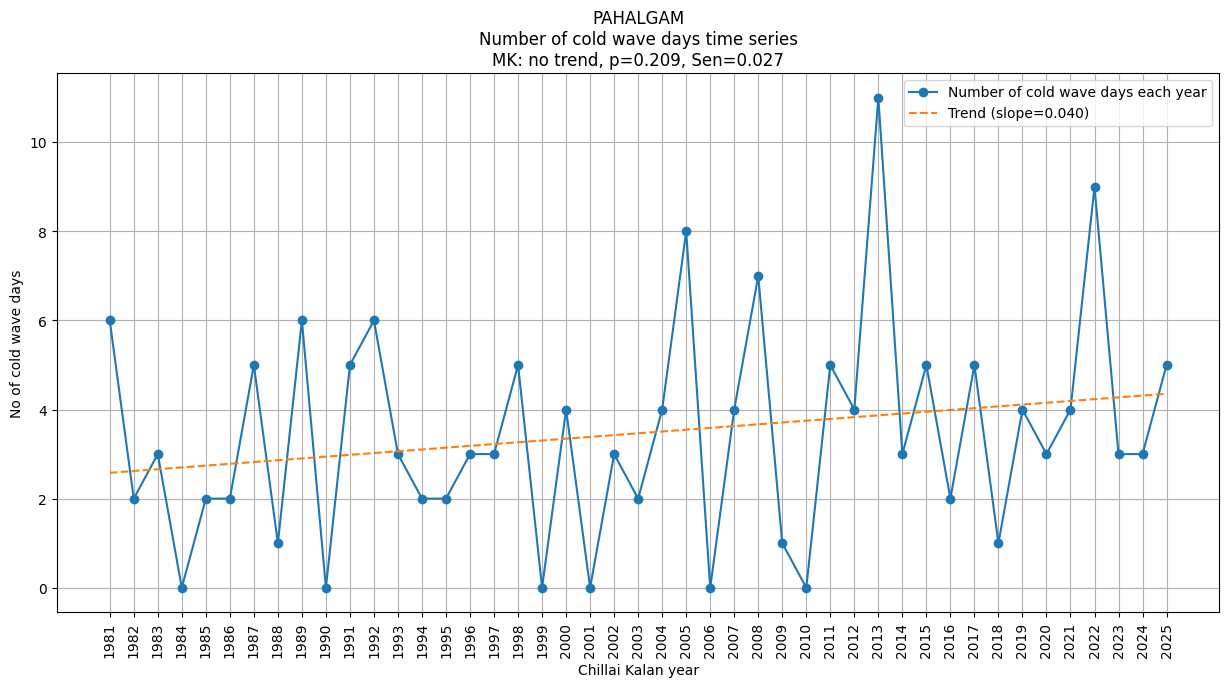

In [17]:
'''Plotting of no of cold wave days for each station'''

def plot_cw(place):
    x = []
    z = []
    for y in range (1981,2026):
        x.append(y)
        z.append(cw[place][y])
    
    plt.figure(figsize=(15,7))
    x1 = np.array(x)
    z1 = np.array(z)
    m, c = np.polyfit(x1, z1, 1)
    trend = m*x1 + c
    result = mk.original_test(z)
    
    plt.title(f"{place.upper()}\n"f"Number of cold wave days time series"f"\nMK: {result.trend}, "f"p={result.p:.3f}, "f"Sen={result.slope:.3f}")
    plt.plot(x, z, marker="o", linestyle="-", label="Number of cold wave days each year")
    plt.plot(x, trend, '--', label=f"Trend (slope={m:.3f})")

    plt.xlabel("Chillai Kalan year")
    plt.xticks(x, rotation=90)
    plt.ylabel("No of cold wave days")
    
    plt.grid(True)
    plt.legend()
    plt.show()
    
#for n in stations:
    #plot_cw(n)
plot_cw("pahalgam")

In [18]:
'''Plotting of no of frost days for each station'''

def plot_fd(place):
    x = []
    z = []
    for y in range (1981,2026):
        x.append(y)
        z.append(fd[place][y])
    
    plt.figure(figsize=(15,7))
    x1 = np.array(x)
    z1 = np.array(z)
    m, c = np.polyfit(x1, z1, 1)
    trend = m*x1 + c
    result = mk.original_test(z)
    
    plt.title(f"{place.upper()}\n"f"Number of Frost days time series"f"\nMK: {result.trend}, "f"p={result.p:.3f}, "f"Sen={result.slope:.3f}")
    plt.plot(x, z, marker="o", linestyle="-", label="Number of Frost days each year")
    plt.plot(x, trend, '--', label=f"Trend (slope={m:.3f})")

    plt.xlabel("Chillai Kalan year")
    plt.xticks(x, rotation=90)
    plt.ylabel("No of cold wave days")
    
    plt.grid(True)
    plt.legend()
    plt.show()

#plot_fd("pahalgam")

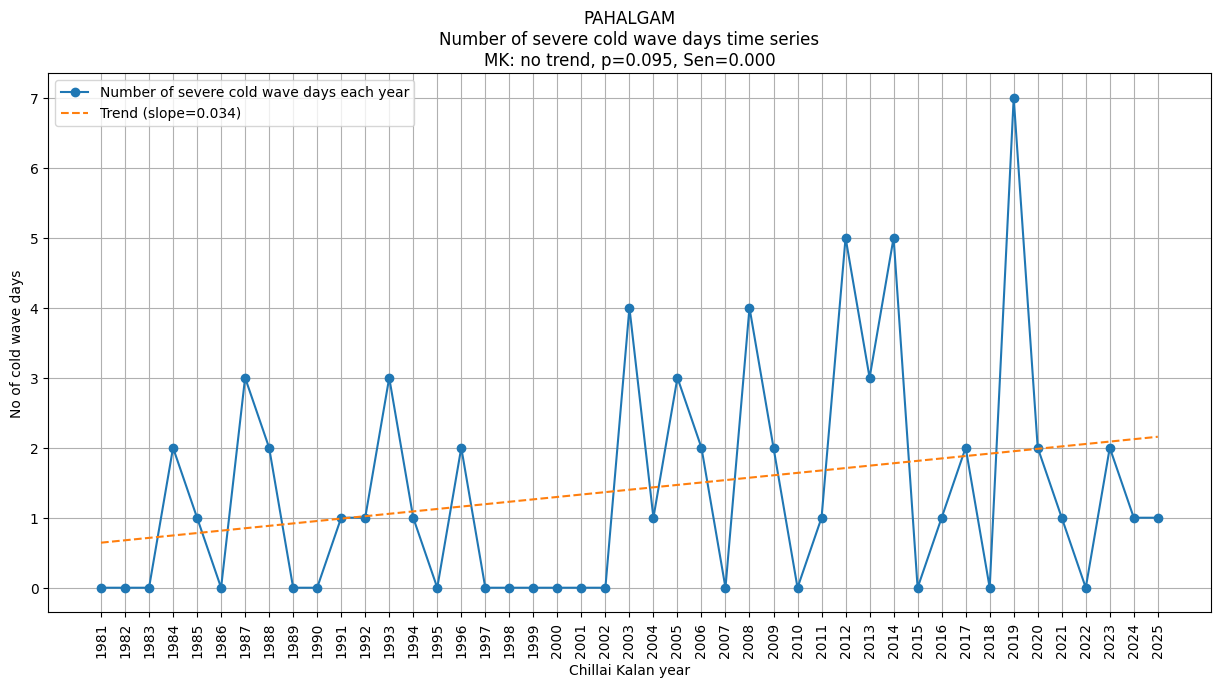

In [19]:
'''Plotting of no of severe cold wave days for each station'''

def plot_scw(place):
    x = []
    z = []
    for y in range (1981,2026):
        x.append(y)
        z.append(scw[place][y])
    
    plt.figure(figsize=(15,7))
    x1 = np.array(x)
    z1 = np.array(z)
    m, c = np.polyfit(x1, z1, 1)
    trend = m*x1 + c
    result = mk.original_test(z)
    
    plt.title(f"{place.upper()}\n"f"Number of severe cold wave days time series"f"\nMK: {result.trend}, "f"p={result.p:.3f}, "f"Sen={result.slope:.3f}")
    plt.plot(x, z, marker="o", linestyle="-", label="Number of severe cold wave days each year")
    plt.plot(x, trend, '--', label=f"Trend (slope={m:.3f})")

    plt.xlabel("Chillai Kalan year")
    plt.xticks(x, rotation=90)
    plt.ylabel("No of cold wave days")
    
    plt.grid(True)
    plt.legend()
    plt.show()

plot_scw("pahalgam")

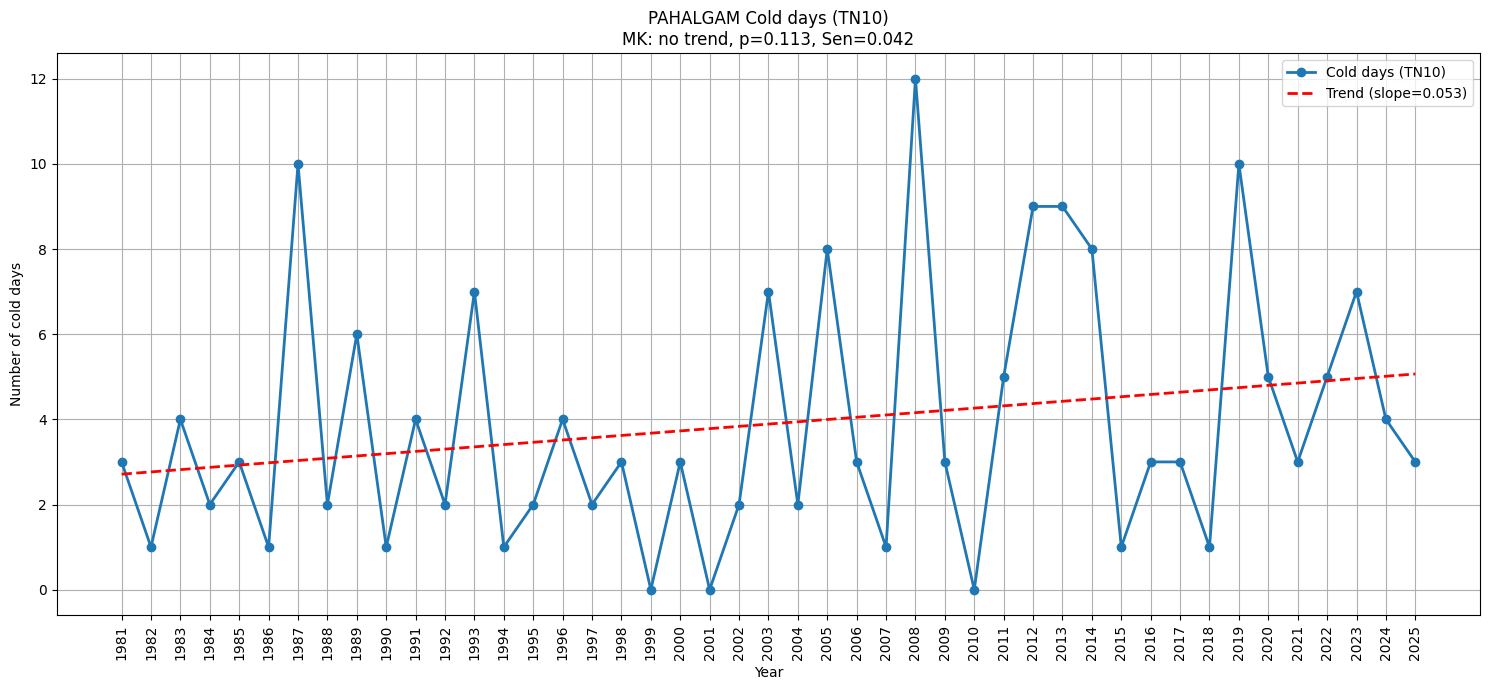

In [20]:
'''To plot trends calculated by 10th percentile method'''

def plot_tn10(place):

    years = np.arange(1981, 2026)
    cd = [tn10[place][y] for y in years]

    m, c = np.polyfit(years, cd, 1)
    trend = m*years + c
    
    result = mk.original_test(cd)
    plt.figure(figsize=(15,7))

    plt.plot(years, cd, marker='o', linewidth=2, label='Cold days (TN10)')

    plt.plot(years, trend, 'r--', linewidth=2, label=f'Trend (slope={m:.3f})')

    plt.xlabel("Year")
    plt.xticks(years, rotation=90)
    plt.ylabel("Number of cold days")
    plt.title(f"{place.upper()} Cold days (TN10)\nMK: {result.trend}, "f"p={result.p:.3f}, "f"Sen={result.slope:.3f}")
    plt.grid(True)
    plt.legend()
    plt.tight_layout()
    plt.show()

plot_tn10("pahalgam")

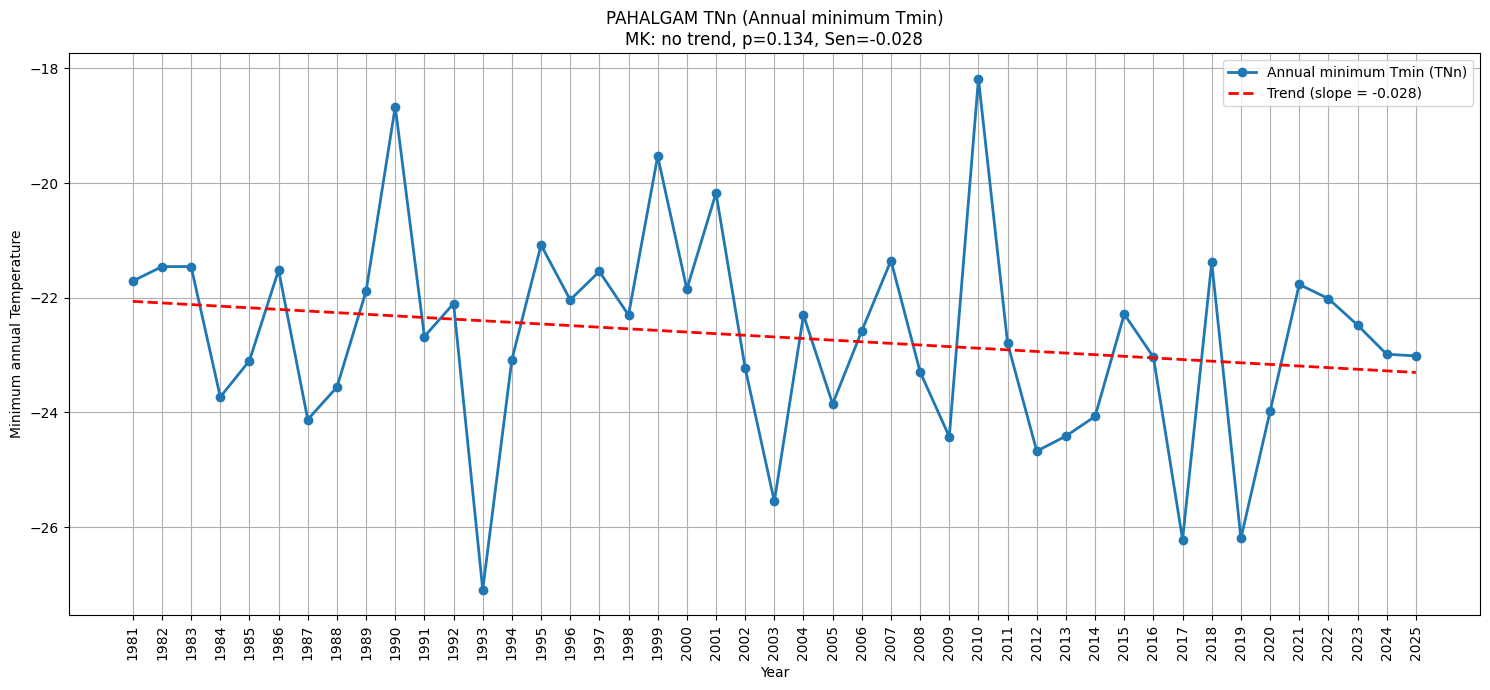

In [27]:
'''Plotting TNn (minimum annual Tmin for each season)'''
def plot_tnn(place):
    years = np.arange(1981, 2026)
    z = [tnn[place][y] for y in years]

    m, c = np.polyfit(years, z, 1)
    trend = m*years + c
    
    result = mk.original_test(z)
    plt.figure(figsize=(15,7))
    plt.plot(years, z, marker = 'o', linewidth = 2, label = 'Annual minimum Tmin (TNn)')
    plt.plot(years, trend, 'r--', linewidth = 2, label= f'Trend (slope = {m : .3f})')

    plt.xlabel("Year")
    plt.xticks(years, rotation=90)
    plt.ylabel("Minimum annual Temperature")
    plt.title(f"{place.upper()} TNn (Annual minimum Tmin)\nMK: {result.trend}, "f"p={result.p:.3f}, "f"Sen={result.slope:.3f}")
    plt.grid(True)
    plt.legend()
    plt.tight_layout()
    plt.show()

plot_tnn("pahalgam")


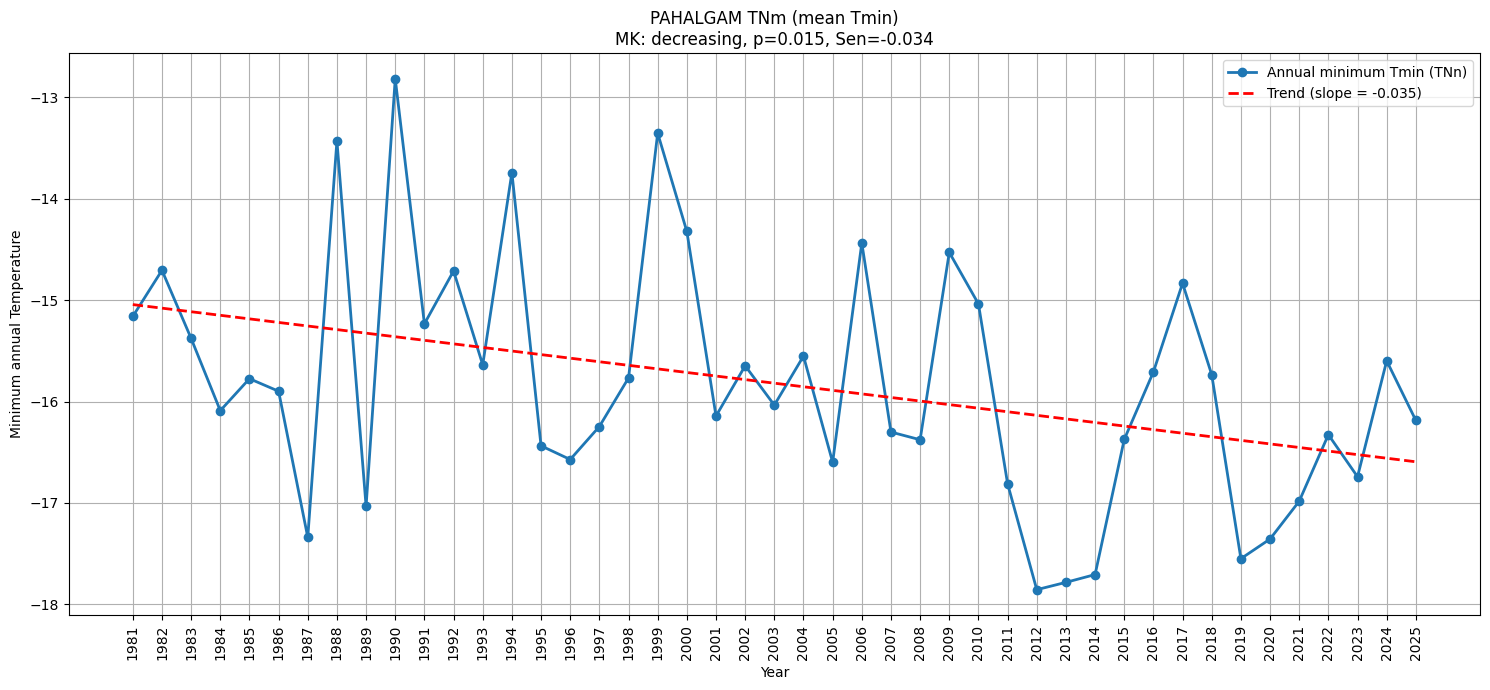

In [28]:
'''Plotting TMm (mean Tmin for each season)'''
def plot_tnn(place):
    years = np.arange(1981, 2026)
    z = [tnm[place][y] for y in years]

    m, c = np.polyfit(years, z, 1)
    trend = m*years + c
    
    result = mk.original_test(z)
    plt.figure(figsize=(15,7))
    plt.plot(years, z, marker = 'o', linewidth = 2, label = 'Annual minimum Tmin (TNn)')
    plt.plot(years, trend, 'r--', linewidth = 2, label= f'Trend (slope = {m : .3f})')

    plt.xlabel("Year")
    plt.xticks(years, rotation=90)
    plt.ylabel("Minimum annual Temperature")
    plt.title(f"{place.upper()} TNm (mean Tmin)\nMK: {result.trend}, "f"p={result.p:.3f}, "f"Sen={result.slope:.3f}")
    plt.grid(True)
    plt.legend()
    plt.tight_layout()
    plt.show()

plot_tnn("pahalgam")


In [23]:
'''Creating a csv file for all the stations with their respective climate indices'''

import pandas as pd

stations = ["srinagar","gulmarg","pahalgam","baramulla","kupwara","qazigund"]
rows = []

for station in stations:
    for year in range(1981, 2026):

        rows.append({"CK year": year, "Station": station.title(), "CWD": cw[station][year],"SCWD": scw[station][year],
                     "FD": fd[station][year], "TNn": round(tnn[station][year].item(), 2), "TNm": round(tnm[station][year].item(), 2),
                     "TN10p": tn10[station][year], "TN90p": tn90[station][year], "CSDI": csdi[station][year],
                     "DTR": round(dtr_mean[station][year].item(), 2)})

# Create DataFrame
df = pd.DataFrame(rows)

# Arrange columns exactly as required
df = df[["CK year", "Station", "CWD", "SCWD", "FD", "TNn", "TNm", "TN10p", "TN90p", "CSDI", "DTR"]]

# Save as CSV
df.to_csv("Climate_Indices_All_Stations.csv", index=False)

# Save as Excel
df.to_excel("Climate_Indices_All_Stations.xlsx", index=False)

print(df.head())

   CK year   Station  CWD  SCWD  FD    TNn   TNm  TN10p  TN90p  CSDI    DTR
0     1981  Srinagar    2     0  36 -12.03 -4.48      4      7     0   7.17
1     1982  Srinagar    1     0  40  -9.38 -4.59      1      1     0  10.50
2     1983  Srinagar    0     0  39  -9.53 -5.15      2      3     0   6.82
3     1984  Srinagar    7     0  40 -10.83 -7.37      8      1     3   8.17
4     1985  Srinagar    1     1  40 -11.28 -5.98      7      2     0   7.10


In [24]:
print(type(cw["srinagar"][1981]))
print(type(scw["srinagar"][1981]))
print(type(fd["srinagar"][1981]))

print(type(tnn["srinagar"][1981]))
print(type(tnm["srinagar"][1981]))

print(type(tn10["srinagar"][1991]))
print(type(tn90["srinagar"][1991]))

print(type(csdi["srinagar"][1981]))
print(type(dtr_mean["srinagar"][1981]))


<class 'int'>
<class 'int'>
<class 'int'>
<class 'numpy.ndarray'>
<class 'numpy.ndarray'>
<class 'int'>
<class 'int'>
<class 'int'>
<class 'numpy.float64'>


In [25]:
import pandas as pd
import pymannkendall as mk

stations = ["srinagar","gulmarg","pahalgam","baramulla","kupwara","qazigund"]

indices = {"Cold Wave Days": cw, "Severe Cold Wave Days": scw, "Frost Days": fd, 
           "Lowest minimum temperature": tnn, "Mean minimum temperature": tnm, "cool nights": tn10, "warm nights": tn90, 
           "Cold Spell Duration Indicator": csdi, "Diurnal Temperature Range": dtr_mean}
rows = []

for station in stations:

    for index_name, data_dict in indices.items():

        series = []

        for year in range(1981, 2026):

            value = data_dict[station][year]

            # Convert numpy array to float if needed
            if hasattr(value, "item"):
                value = value.item()

            series.append(value)

        result = mk.original_test(series)

        rows.append({ "Station": station.title(), "Index": index_name, "MK Trend": result.trend,
            "Kendall Tau": round(result.Tau, 3), "p-value": round(result.p, 4), "Sen's Slope": round(result.slope, 4), 
            "Significant (α=0.05)": "Yes" if result.p <= 0.05 else "No" })

trend_df = pd.DataFrame(rows)

trend_df.to_csv("Trend Summary.csv", index=False)
trend_df.to_excel("Trend Summary.xlsx", index=False)

In [26]:
import pandas as pd
import numpy as np

stations = ["srinagar","gulmarg","pahalgam","baramulla","kupwara","qazigund"]
rows = []

for station in stations:

    mean_tmin = np.mean([float(tnm[station][year].item()) for year in range(1981, 2026)])

    lowest_tmin = np.min([float(tnn[station][year].item()) for year in range(1981, 2026)])

    mean_cwd = np.mean([cw[station][year] for year in range(1981, 2026)])

    mean_scwd = np.mean([scw[station][year] for year in range(1981, 2026)])

    mean_fd = np.mean([fd[station][year] for year in range(1981, 2026)])

    mean_tn10 = np.mean([tn10[station][year] for year in range(1981, 2026)])

    mean_tn90 = np.mean([tn90[station][year] for year in range(1981, 2026)])

    mean_csdi = np.mean([csdi[station][year] for year in range(1981, 2026)])

    mean_dtr = np.mean([dtr_mean[station][year] for year in range(1981, 2026)])

    rows.append({
        "Station": station.title(),
        "Mean Tmin (°C)": round(mean_tmin, 2),
        "Lowest Tmin (°C)": round(lowest_tmin, 2),
        "Mean Cold Wave Day": round(mean_cwd, 2),
        "Mean Severe Cold Wave Day": round(mean_scwd, 2),
        "Mean Frost Day": round(mean_fd, 2),
        "Mean cool nights": round(mean_tn10, 2),
        "Mean warm nights": round(mean_tn90, 2),
        "Mean Cold Spell Duration Index": round(mean_csdi, 2),
        "Mean Diurnal Temperature Range (°C)": round(mean_dtr, 2)
    })

summary_df = pd.DataFrame(rows)

summary_df.to_csv("Station_Comparison_Summary.csv", index=False)
summary_df.to_excel("Station_Comparison_Summary.xlsx", index=False)

print(summary_df)

     Station  Mean Tmin (°C)  Lowest Tmin (°C)  Mean Cold Wave Day  \
0   Srinagar           -5.14            -14.14                2.36   
1    Gulmarg           -7.46            -19.97                1.71   
2   Pahalgam          -15.82            -27.09                3.47   
3  Baramulla           -5.15            -16.42                1.84   
4    Kupwara           -7.98            -20.60                1.36   
5   Qazigund           -5.81            -19.08                2.87   

   Mean Severe Cold Wave Day  Mean Frost Day  Mean cool nights  \
0                       0.40           38.36              3.76   
1                       0.93           39.87              3.64   
2                       1.40           40.00              3.89   
3                       0.96           36.71              3.58   
4                       1.04           39.84              3.69   
5                       1.69           38.11              3.98   

   Mean warm nights  Mean Cold Spell Duration 